# Figure 1 · Cây và neural theo ngân sách HPO

**Nguồn chính** · Kết quả từng lượt do tác giả công bố. Notebook chạy lại phép phân tích và vẽ hình bằng Python. Lần mở đầu cần Internet để tải và đối chiếu SHA-256.

## Cách đọc thí nghiệm

Bốn nhóm benchmark medium. Dùng default ở hạng 0, sau đó chọn cấu hình theo điểm validation tốt nhất sau mỗi lượt. Điểm test chuẩn hóa theo từng bộ dữ liệu, bằng phân vị 10% cho phân loại và trung vị cho hồi quy. Phần âm của điểm test hồi quy được chặn ở 0 như script. Dải màu là min–max qua 15 lần xáo thứ tự.

In [1]:
from pathlib import Path
import sys

root = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "src/analysis.py").is_file())
sys.path.insert(0, str(root))
from IPython.display import Image, display
import matplotlib.pyplot as plt
from src.analysis import analyze
from src.author_data import SOURCES, prepare
from src.plots import export, export_project

source = "benchmark"
cache = prepare(source)
print("SHA-256 nguồn:", SOURCES[source].sha256)

SHA-256 nguồn: 6d709ae8e10ece7f0a66260ae0f2d8f5d914aed97ce5ab8e7674e654ed6ec1e4


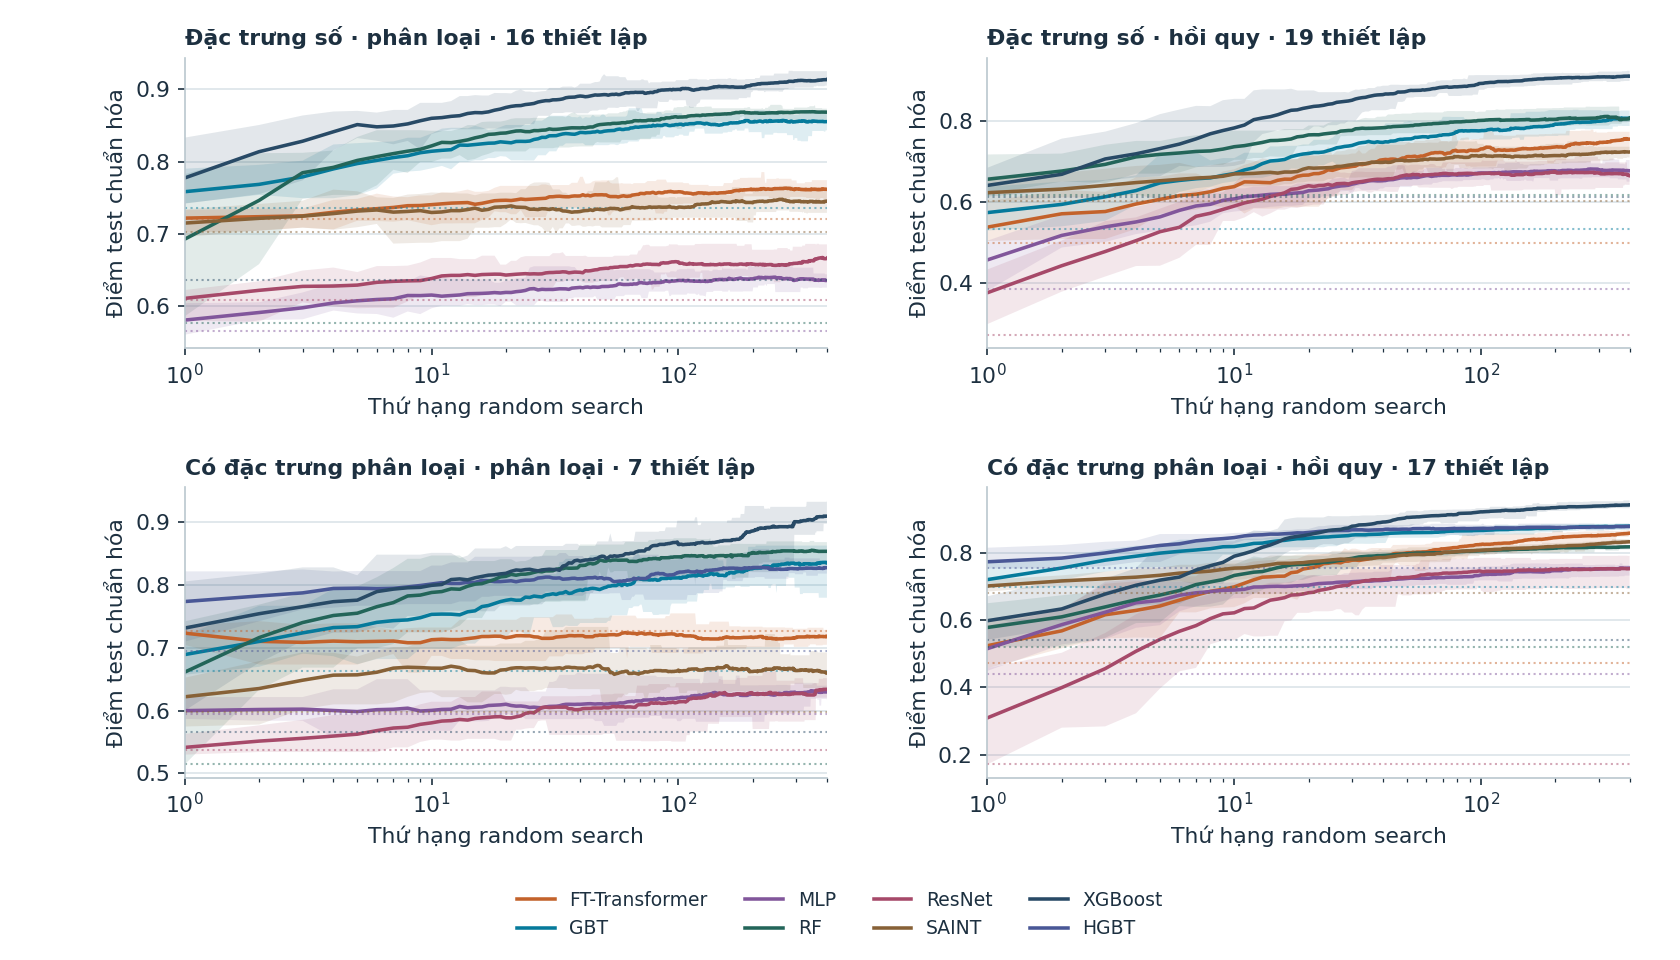

In [2]:
figure_number = 1
scores = analyze(figure_number)
chart = export(figure_number, scores)
plt.close(chart)
display(Image(filename=str(root / "figures" / f"figure_{figure_number:02d}.png")))

## Một số giá trị đứng sau biểu đồ

In [3]:
display(scores.head(8).round(5))

,rank,model_name,mean,count,low,high,panel,datasets
0,0,FT Transformer,0.72030,15,0.72030,0.72030,numerical_classification_medium,16
1,0,GradientBoostingTree,0.73578,15,0.73578,0.73578,numerical_classification_medium,16
2,0,MLP,0.56578,15,0.56578,0.56578,numerical_classification_medium,16
3,0,RandomForest,0.57665,15,0.57665,0.57665,numerical_classification_medium,16
4,0,Resnet,0.60908,15,0.60908,0.60908,numerical_classification_medium,16
5,0,SAINT,0.70265,15,0.70265,0.70265,numerical_classification_medium,16
6,0,XGBoost,0.63577,15,0.63577,0.63577,numerical_classification_medium,16
7,1,FT Transformer,0.72179,15,0.70191,0.73290,numerical_classification_medium,16


## Đối chứng do nhóm tự train

Đối chứng V2 + mở rộng có 24/57 thiết lập đủ dữ liệu. Ngân sách random chung theo bốn nhóm lần lượt là 2, 3, 29 và 22 ngoài default. Bảng và đường cong dùng bản tổng hợp đã kiểm chứng của dự án.

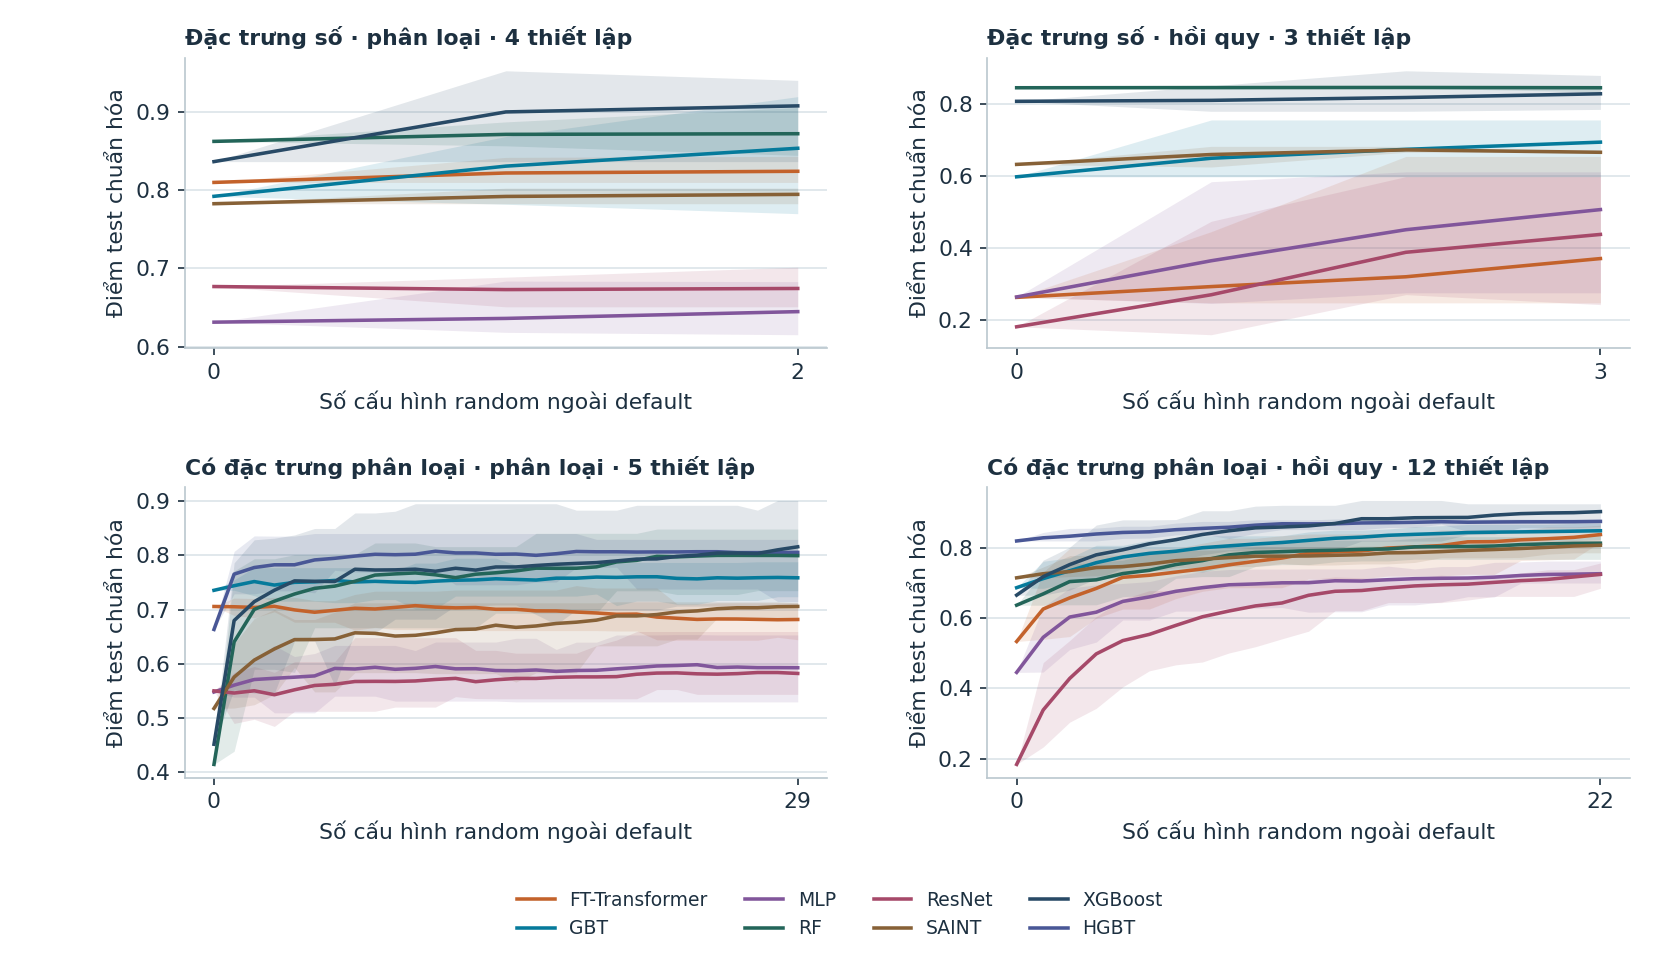

In [4]:
chart = export_project(figure_number)
plt.close(chart)
display(Image(filename=str(root / "figures" / f"figure_{figure_number:02d}_v2.png")))

## Quy trình train trong repo tác giả

**Minh họa quy trình, không có fit mới ở notebook này.** Điểm vào: `src/launch_benchmarks/launch_benchmarks.py`. Chọn nhóm OpenML, model và cấu hình công bố; chia train/validation/test; train; lưu điểm từng split.

Nếu tái chạy độc lập, dùng cấu hình đầy đủ của đúng model, task và điều kiện từ CSV nguồn. Repo gốc có lệnh chuẩn bị môi trường, launcher và `train_model_on_config`; khóa phiên bản source trước khi chạy. 

## Nguồn

- [Paper NeurIPS 2022](https://papers.neurips.cc/paper_files/paper/2022/hash/0378c7692da36807bdec87ab043cdadc-Abstract-Datasets_and_Benchmarks.html)
- [Repo tác giả, commit đã đối chiếu](https://github.com/LeoGrin/tabular-benchmark/tree/9d54cf53d9fd3159e367e70a00005f4fcbf2c79d)
